# 04 · Novelty detection and the frozen test

**Part A** asks whether models that learn only what *normal* telemetry looks like can compete with supervised
models, and whether they help where the supervised model is weak.
**Part B** scores the pre-registered candidates on the publisher's frozen test split — **once**.

Reproduce:
```
python -m satelliteguard.models.tune pca_recon
python -m satelliteguard.models.tune iforest
python -m satelliteguard.models.train pca_recon iforest
python -m satelliteguard.evaluation.compare hgb pca_recon
python -m satelliteguard.evaluation.evaluate_test     # refuses to run twice (reports/test_lock.json)
python -m satelliteguard.evaluation.plots
```

In [1]:
import json
import pandas as pd
from IPython.display import Image, display
from satelliteguard import load_config

cfg = load_config()
P, FIG = cfg["paths"], cfg["paths"]["figures"]
M = json.loads(P["metrics"].read_text())
C = json.loads((P["metrics"].parent / "comparisons.json").read_text())
show = lambda name: display(Image(filename=str(FIG / f"{name}.png")))
TRACKS = ["logreg", "hgb", "pca_recon", "iforest"]

# Part A — Novelty track (train split, episode-grouped CV)

Both models are **fit on normal training segments only** and score how far a segment departs from normal behaviour.
Labels are used only to pick one hyperparameter (one-SE rule) and the review threshold — never to fit the model.
Inputs: quantile-scaled numeric features, **no channel**.

| Model | Idea |
|---|---|
| **PCA reconstruction** | Project onto the main directions of variation of normal segments; anomalies reconstruct poorly. Score = squared reconstruction error. |
| **Isolation Forest** | Random axis-aligned splits isolate unusual points in fewer steps. Score = −mean path length (normalised). |

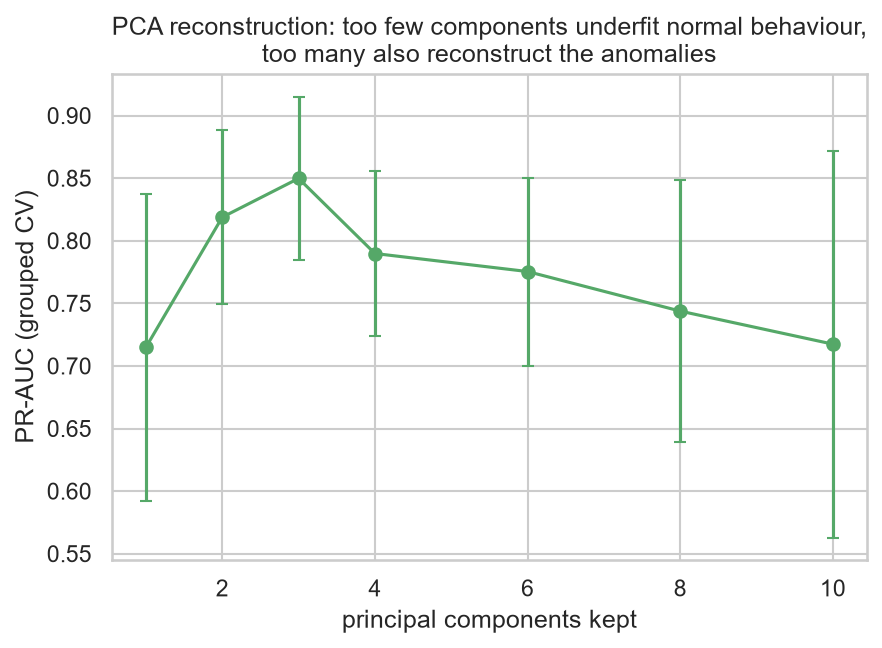

In [2]:
show("21_pca_components")

The number of components shows a clear bias–variance-style U-shape. With 1 component the model cannot describe
normal behaviour, so normal segments also reconstruct badly. With many components the subspace becomes rich enough to
reconstruct anomalies too. **3 components** is best (PR-AUC 0.85).

In [3]:
pd.DataFrame({n: {
    "track": M["cv"][n]["track"],
    "PR-AUC": f"{M['cv'][n]['cv_folds']['pr_auc_mean']:.3f} ± {M['cv'][n]['cv_folds']['pr_auc_std']:.3f}",
    "ROC-AUC": M["cv"][n]["cv_folds"]["roc_auc_mean"],
    "precision@policy": M["cv"][n]["cv_oof_at_threshold"]["precision"],
    "recall@policy": M["cv"][n]["cv_oof_at_threshold"]["recall"],
} for n in ["prevalence", "channel_only", *TRACKS]}).T

,track,PR-AUC,ROC-AUC,precision@policy,recall@policy
prevalence,reference,0.201 ± 0.002,0.5,0.2032,0.9844
channel_only,reference,0.250 ± 0.050,0.4853,0.2181,1.0
logreg,supervised,0.878 ± 0.078,0.9446,0.827,0.8193
hgb,supervised,0.919 ± 0.060,0.9605,0.8154,0.8255
pca_recon,unsupervised,0.850 ± 0.065,0.9346,0.6754,0.8037
iforest,unsupervised,0.611 ± 0.160,0.8462,0.4149,0.8349


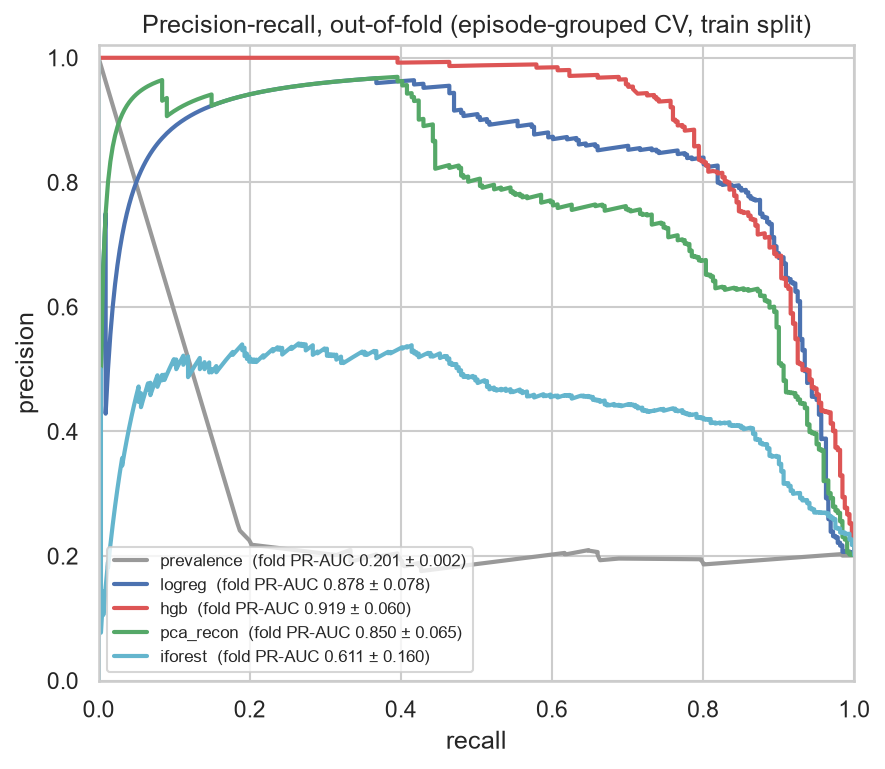

,mean_diff,folds_a_better,n_folds,p_naive,p_corrected
hgb_vs_logreg_pr_auc,0.0402,11,15,0.0336,0.298
hgb_vs_pca_recon_pr_auc,0.069,14,15,0.0002,0.0344
pca_recon_vs_logreg_pr_auc,-0.0287,6,15,0.143,0.4882


In [4]:
show("25_cv_pr_all_tracks")
pd.DataFrame({k: v for k, v in C.items() if k.endswith("pr_auc")}).T[
    ["mean_diff", "folds_a_better", "n_folds", "p_naive", "p_corrected"]]

- **PCA reconstruction (0.850)** is close to the supervised logistic model (0.878; corrected p = 0.49, a tie) despite
  never seeing a label during fitting.
- **Gradient boosting beats PCA** in 14/15 folds; this difference *survives* the Nadeau–Bengio correction (p = 0.034).
  Knowing what anomalies look like helps.
- **Isolation Forest is weak and unstable (0.61 ± 0.16).**
- `contamination` is not tuned: in sklearn it only sets the cut-off for `predict()`, which we never use. All metrics
  come from `score_samples` and our own threshold policy, so contamination cannot change any reported number.

## Do the tracks complement each other?

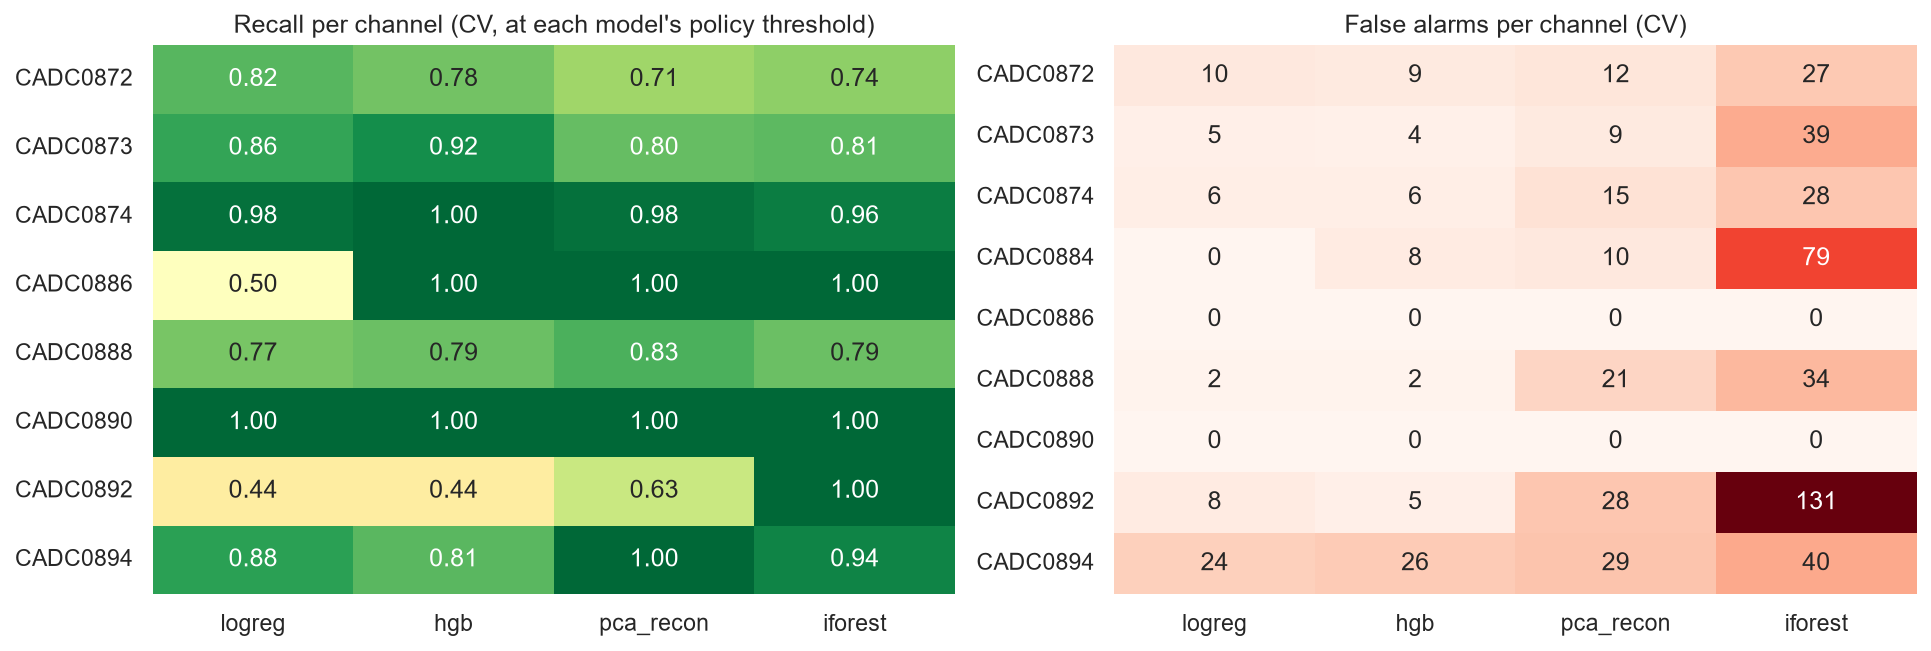

In [5]:
show("22_cv_channel_recall")

- On the supervised model's weakest channel (**CADC0892**, recall 0.44), PCA reaches 0.63 — at the cost of 28 false
  alarms instead of 5. Across all channels PCA flags **17 of the 56 anomalies boosting misses**.
- **Isolation Forest flags every normal CADC0892 segment (131)** and 79 on CADC0884, which has no anomalies at all.
  Without channel information, a global novelty model treats "this channel's normal operating range is unusual" as
  "anomalous". A channel-normalised or per-channel novelty model is the obvious fix (future work).

**Decision:** gradient boosting stays primary; PCA reconstruction is shown in the dashboard as a **second-opinion
novelty score**, useful when a segment looks unlike anything normal even though the supervised model is unsure.

# Part B — Frozen test (run once)

Pre-registered in `docs/decision_log.md` *before* scoring: candidates, primary model (hgb), thresholds fixed from
train OOF predictions, nothing changed afterwards. The lock file records when and on which commit it ran:

In [6]:
print((P["metrics"].parent / "test_lock.json").read_text())

{
  "evaluated_utc": "2026-11-24T15:28:29+00:00",
  "git_commit": "ad0e08c63c6257be1979af3c6b497b24c954a2c6+uncommitted",
  "candidates": [
    "prevalence",
    "channel_only",
    "logreg",
    "hgb",
    "pca_recon",
    "iforest"
  ],
  "primary": "hgb",
  "n_test_segments": 529,
  "forced": false
}


In [7]:
T = M["test"]
pd.DataFrame({n: {
    "PR-AUC": T[n]["overall"]["pr_auc"],
    "95% CI (episode bootstrap)": T[n]["bootstrap"]["pr_auc_ci95"],
    "precision": T[n]["overall"]["precision"],
    "recall": T[n]["overall"]["recall"],
    "F1": T[n]["overall"]["f1"],
    "MCC": T[n]["overall"]["mcc"],
    "alerts": T[n]["overall"]["alerts"],
    "Brier": T[n]["overall"].get("brier"),
} for n in ["prevalence", "channel_only", *TRACKS]}).T

,PR-AUC,95% CI (episode bootstrap),precision,recall,F1,MCC,alerts,Brier
prevalence,0.2136,"[0.1261, 0.2964]",0.2136,1.0,0.352,0.0,529,0.1681
channel_only,0.3171,"[0.1705, 0.5244]",0.2292,1.0,0.3729,0.1408,493,0.1588
logreg,0.9402,"[0.8934, 0.9734]",0.8879,0.8407,0.8636,0.8284,107,0.0438
hgb,0.962,"[0.9408, 0.9849]",0.9151,0.8584,0.8858,0.8568,106,0.0353
pca_recon,0.8817,"[0.8133, 0.95]",0.7561,0.823,0.7881,0.7285,123,None
iforest,0.712,"[0.5432, 0.8505]",0.5636,0.823,0.6691,0.575,165,None


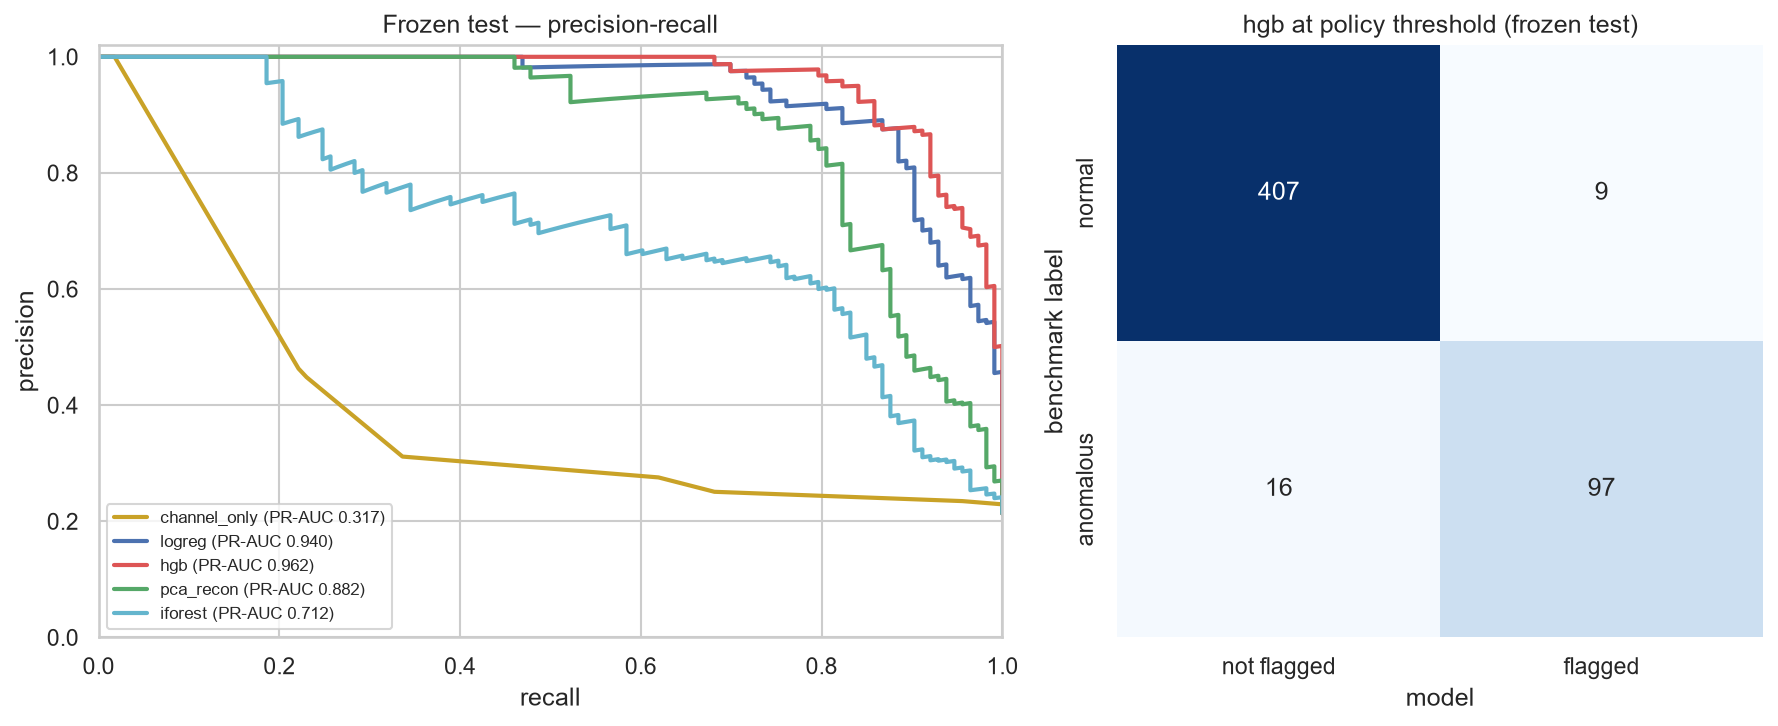

In [8]:
show("24_test_pr_confusion")

**Primary model (gradient boosting) on 529 unseen test segments: PR-AUC 0.962 (95% CI 0.941–0.985),
precision 0.92, recall 0.86** at the pre-declared threshold. The model ranking is identical to CV:
boosting > logistic > PCA > Isolation Forest > channel-only > prevalence.

## Why are test scores *higher* than cross-validation?

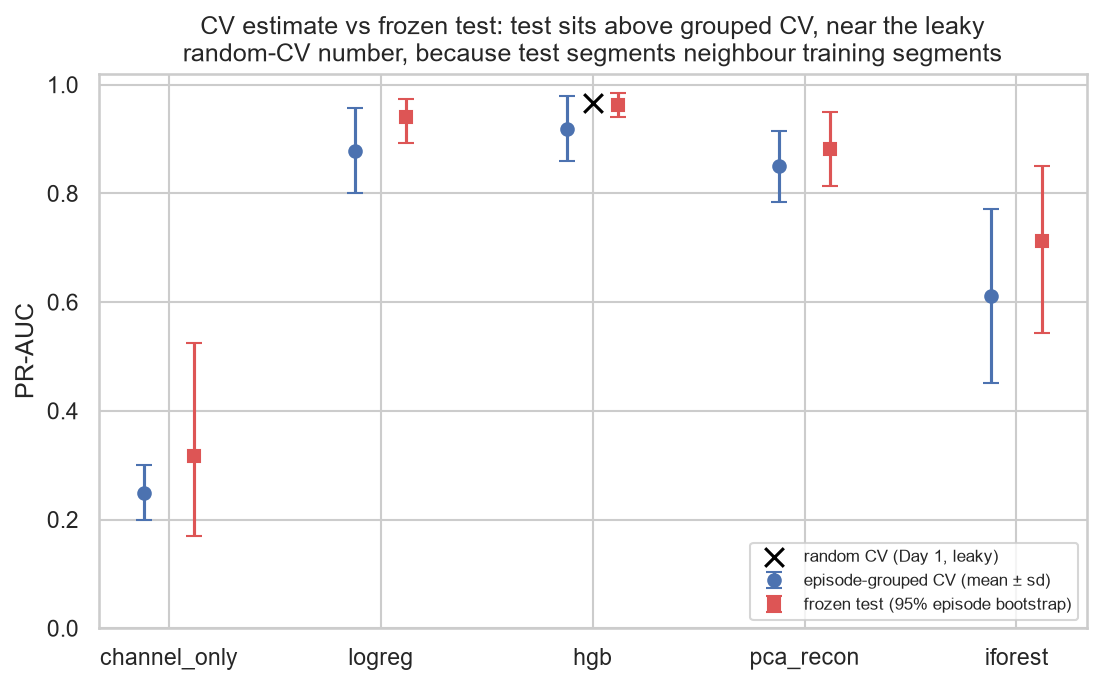

In [9]:
show("23_cv_vs_test")

Every model scores higher on the test split than in episode-grouped CV, and boosting's test score (0.962) is almost
exactly what **random** CV predicted on Day 1 (0.967).

This is the neighbour-leakage finding from notebook 01, now confirmed out of sample. 89% of test segments are adjacent
to a training segment, and the final models are trained on all of those neighbours. The publisher's test split
therefore measures performance on **interleaved** data. Our grouped-CV estimate (≈0.92) is the more honest guess for
**new, unseen episodes**.

We report both numbers: test for comparability with the published benchmark, grouped CV as the generalisation
estimate.

In [10]:
iso = {n: T[n]["isolated_segments"] for n in ["logreg", "hgb", "pca_recon"]}
pd.DataFrame(iso).T[["n", "prevalence", "pr_auc", "precision", "recall"]]

,n,prevalence,pr_auc,precision,recall
logreg,56.0,0.3571,0.9593,1.0,0.70
hgb,56.0,0.3571,0.9951,1.0,0.85
pca_recon,56.0,0.3571,0.9559,1.0,0.80


On the **56 test segments that touch no training segment**, boosting still reaches PR-AUC 0.995. The subset is small
(20 anomalies) and not representative (36% anomalous vs 21% overall), so it cannot settle the question. It does show
that performance does not collapse away from training neighbours. These are features of each segment alone; the model
never sees a neighbour's label.

## Per-channel test results (primary model)

In [11]:
pc = T["hgb"]["per_channel"]
pd.DataFrame(pc).T.reindex(columns=["n", "prevalence", "pr_auc", "precision", "recall", "alerts", "anomalies", "flagged"])

,n,prevalence,pr_auc,precision,recall,alerts,anomalies,flagged
CADC0872,132.0,0.2424,0.9709,0.9032,0.8750,31.0,NaN,NaN
CADC0873,153.0,0.2026,0.9750,0.9333,0.9032,30.0,NaN,NaN
CADC0874,52.0,0.4423,0.9946,1.0000,0.7391,17.0,NaN,NaN
CADC0884,36.0,NaN,NaN,NaN,NaN,NaN,0.0,0.0
CADC0886,4.0,0.2500,1.0000,1.0000,1.0000,1.0,NaN,NaN
CADC0888,64.0,0.1875,0.9755,1.0000,0.9167,11.0,NaN,NaN
CADC0890,2.0,NaN,NaN,NaN,NaN,NaN,2.0,2.0
CADC0892,53.0,0.1321,0.9048,1.0000,0.8571,6.0,NaN,NaN
CADC0894,33.0,0.1515,0.7544,0.5000,0.8000,8.0,NaN,NaN


The weak spot identified in CV **replicates on test**: CADC0894 has the lowest PR-AUC (0.75) and precision 0.50
(long, multi-peak normal segments flagged as anomalous). CADC0884 and CADC0890 have only one class in the test split, so
no ranking metric exists there; the table shows their counts instead. CADC0886/0890 have 2–4 test segments, so their
numbers are anecdotal.

## Summary

| | Grouped CV (generalisation estimate) | Frozen test (benchmark) |
|---|---|---|
| Gradient boosting (primary) | 0.919 ± 0.060 | **0.962** [0.941, 0.985]; P 0.92 / R 0.86 |
| Logistic regression | 0.878 ± 0.078 | 0.940 [0.893, 0.973] |
| PCA reconstruction (novelty) | 0.850 ± 0.065 | 0.882 [0.813, 0.950] |
| Isolation Forest (novelty) | 0.611 ± 0.160 | 0.712 [0.543, 0.851] |
| Channel only (reference) | 0.250 ± 0.050 | 0.317 |

- Supervised boosting is the best detector; knowing anomaly patterns beats modelling normality alone (significant).
- PCA reconstruction is a strong label-free alternative and catches some anomalies boosting misses → second opinion.
- Isolation Forest without channel normalisation confuses channel scale with anomaly.
- The test split is optimistic because of interleaving; grouped CV is the honest generalisation estimate.